This notebook reproduces Fig. 18. We compute the error between the pulses obtained for the shuttling model (see `Fig11-shuttling_model.ipynb` for more information) by solving the ($\alpha,\beta$) hypergeometry, and their approximation using a basis of functions obtained with the LZ problem (see `Fig06ab-functions_basis.ipynb` and `Fig06cd-three_level_system.ipynb` for more information). The pulses follow the first excited state, and the parameters of the Hamiltonian are the same as in Fig. 11: $\phi_L=0$, $\phi_R=0.8\pi$, $|\Delta_L|/t_c=1$, and $|\Delta_R|/t_c=2$.

Since the spectrum of the shuttling model is not symmetric with respect to $\varepsilon=0$, the pulses are not point symmetric, contrary to the LZ basis functions. Therefore, we use a split basis, such that the approximated pulse is given by
$$
g(\tau) \simeq \sum_n\left[c_n^{(1)}\Theta(-\tau+1/2) + c_n^{(2)}\Theta(\tau-1/2)\right]\,\tilde{f}_n(\tau),
$$
where a linearly independent subset of the split functions is obtained with a QR decomposition (see `HQUAD_lib.utils.split_basis`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from HQUAD_lib.parallel_utils import parameter_run
from HQUAD_lib.QUAD_utils import solve_LZ
from HQUAD_lib.hamiltonians import two_valleys_system
from HQUAD_lib.utils import independent_basis, split_basis, compute_pulse_and_approx

# Basis

In [2]:
alphas_basis = np.linspace(-25, 60, 201)  # Increase to obtain lower errors
alphas_basis[0] = -np.inf
alphas_basis[-1] = np.inf

zs_sol = parameter_run(solve_LZ, 'alpha', alphas_basis, beta=0, reduction=3)
s = np.linspace(0, 1, len(zs_sol[0]))
ds = np.abs(s[1] - s[0])

# Independent LZ basis, and split basis
independent_functions, _ = independent_basis(zs_sol, ds)
independent_functions, G_independent = split_basis(independent_functions, ds)

print(f'Number of elements in the split basis: {len(independent_functions)}')

solve_LZ: [['alpha']]:   0%|          | 0/201 [00:00<?, ?it/s]

Number of elements in the split basis: 53


# Shuttling model

In [3]:
tc = 1
phiL = 0
phiR = 0.8 * np.pi
DeltaL = 1
DeltaR = 2

limit_inf = 0
limit_sup = 1e10

adiabatic_state = 1

eps_s = np.linspace(-10, 10, 2 ** 18 + 1)  # 2 ** 20 + 1 points in the manuscript
driving_parameter = eps_s

partial_hamiltonian = np.array([two_valleys_system(1, 0, 0, 0, 0, 0) for _ in range(len(eps_s))])

hypermatrix = np.array([two_valleys_system(eps, tc, phiL, phiR, DeltaL, DeltaR) for eps in eps_s])
eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

parameters_fun = dict(eigvalues=eigvalues, eigmodes=eigmodes, driving_parameter=driving_parameter,
                      partial_hamiltonian=partial_hamiltonian, adiabatic_state=adiabatic_state,
                      independent_functions=independent_functions, G_independent=G_independent, limit_inf=limit_inf,
                      limit_sup=limit_sup)

# Reconstruction error

In [4]:
alphas = np.linspace(-3, 3, 13)  # Increase sample rate to improve resolution (101 values in the manuscript)
betas = np.linspace(-3, 3, 13)  # Increase sample rate to improve resolution (101 values in the manuscript)

pulses = parameter_run(compute_pulse_and_approx, [['alpha'], ['beta']], [[alphas], [betas]], **parameters_fun)
eps_sols = pulses[0].reshape((len(alphas), len(betas), -1))
eps_approxs = pulses[1].reshape((len(alphas), len(betas), -1))

errors = np.sum(np.abs(eps_sols - eps_approxs), axis=-1) * ds

compute_pulse_and_approx: [['alpha'], ['(...)]:   0%|          | 0/169 [00:00<?, ?it/s]

# Plot

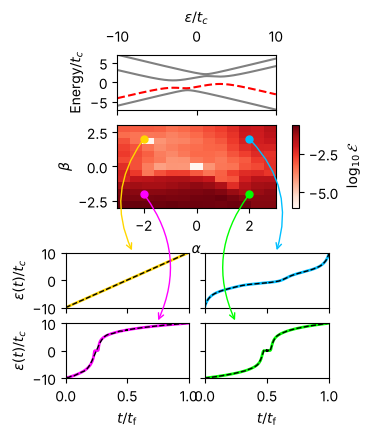

In [5]:
fig, axs = plt.subplot_mosaic([['.', 'B', 'B', '.', '.'],
                               ['.', 'D', 'D', 'CB', '.'],
                               ['.', '.', '.', '.', '.'],
                               ['A', 'A', 'C', 'C', 'C'],
                               ['E', 'E', 'F', 'F', 'F']],
                              figsize=(3.4, 4.2),
                              gridspec_kw=dict(width_ratios=[0.5, 1, 1, 0.1, 0.2],
                                               height_ratios=[1, 1.5, 0.25, 1, 1]))

# -------- Band structure ----------
step = 2 ** 5
for i in range(len(eigvalues.T)):
    if i == adiabatic_state:
        color, ls = 'r', '--'
    else:
        color, ls = 'gray', '-'
    axs['B'].plot(eps_s[::step], eigvalues[::step, i], c=color, ls=ls)

axs['B'].set_xlim(min(eps_s), max(eps_s))
axs['B'].set_ylim(np.min(eigvalues), np.max(eigvalues))
axs['B'].set_xlabel(r'$\varepsilon / t_c$')
axs['B'].set_ylabel(r'Energy$/t_c$')
axs['B'].xaxis.set_label_position('top')
axs['B'].tick_params(labelbottom=False, labeltop=True)

# ------- Error -----------
im = axs['D'].imshow(np.log10(errors.T), origin='lower', extent=[min(alphas), max(alphas), min(betas), max(betas)],
                     cmap='Reds', interpolation='none', aspect='auto', vmin=-6)
axs['D'].set_xlabel(r'$\alpha$')
axs['D'].set_ylabel(r'$\beta$')
cbar = plt.colorbar(im, cax=axs['CB'], label=r'$\log_{10}\mathcal{E}$')

# -------- Approximation -------
axes = [axs['A'], axs['C'], axs['F'], axs['E']]
coordinates = [(-2, 2), (2, 2), (2, -2), (-2, -2)]
end_points = [(0.1, -0.55), (1, -0.55), (0.75, -1.4), (0.25, -1.4)]
colors = ['gold', 'deepskyblue', 'lime', 'fuchsia']
arcs = [0.3, -0.3, 0.3, -0.3]

for i, ax in enumerate(axes):
    alpha, beta = coordinates[i]
    index_alpha = np.argmin(np.abs(alphas - alpha))
    index_beta = np.argmin(np.abs(betas - beta))

    axs['D'].plot(alpha, beta, marker='o', color=colors[i], markersize=5)
    axs['D'].annotate('', xy=end_points[i], xycoords='axes fraction', xytext=(alpha, beta), textcoords='data',
                      arrowprops=dict(arrowstyle='->', color=colors[i], connectionstyle=f'arc3,rad={arcs[i]}'),
                      zorder=1000, annotation_clip=False)

    ax.plot(s, eps_sols[index_alpha, index_beta], c=colors[i], lw=2, label='Original func.')
    ax.plot(s, eps_approxs[index_alpha, index_beta], 'k--', lw=1, label='Approx. func.')
    ax.set_xlim(0, 1)
    ax.set_ylim(-10, 10)
    ax.set_ylabel(r'$\varepsilon(t) / t_c$')

for ax in axes:
    ax.set_zorder(0)
axs['D'].set_zorder(2)

for ax in [axs['C'], axs['F']]:
    ax.set_ylabel('')
    ax.set_yticklabels([])

for ax in [axs['E'], axs['F']]:
    ax.set_xlabel(r'$t / t_\mathrm{f}$')

for ax in [axs['A'], axs['C']]:
    ax.set_xticklabels([])

fig.subplots_adjust(wspace=0.4, hspace=0.3)